# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset dapat diperoleh dari berbagai sumber, seperti public repositories (*Kaggle*, *UCI ML Repository*, *Open Data*) atau data primer yang Anda kumpulkan sendiri.


### Bank Marketing Dataset

This project uses the **Bank Marketing** dataset (`bank-additional-full.csv`). It records the direct phone marketing campaigns that a Portuguese bank ran between May 2008 and November 2010. Each row is one call to one client. The goal is to predict whether that client subscribed to a term deposit.

- **Source:** UCI Machine Learning Repository, [Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing) (Moro, Cortez & Rita, 2014). A copy is also on [Kaggle](https://www.kaggle.com/datasets/volodymyrgavrysh/bank-marketing-campaigns-dataset).
- **Size:** 41,188 rows × 21 columns, with `;` as the separator.
- **Target:** `y` ("yes" / "no"): did the client subscribe to a term deposit?

**Feature groups**

| Group | Columns |
|---|---|
| Client profile | `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` |
| Last contact of the current campaign | `contact`, `month`, `day_of_week`, `duration` |
| Campaign history | `campaign`, `pdays`, `previous`, `poutcome` |
| Socio-economic context | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` |

In several categorical columns, missing values are written as the string `"unknown"` instead of being left empty.

In [1]:
DATASET_INFO = {
    "name": "Bank Marketing (bank-additional-full.csv)",
    "source": "https://archive.ics.uci.edu/dataset/222/bank+marketing",
    "rows x columns": "41,188 x 21",
    "separator": ";",
    "target": "y (subscribed to a term deposit: yes/no)",
}
for key, value in DATASET_INFO.items():
    print(f"{key:>15}: {value}")

           name: Bank Marketing (bank-additional-full.csv)
         source: https://archive.ics.uci.edu/dataset/222/bank+marketing
 rows x columns: 41,188 x 21
      separator: ;
         target: y (subscribed to a term deposit: yes/no)


# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [2]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, RobustScaler

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [3]:
RAW_PATH = "../bankmarketing_raw/bank-additional-full.csv"

df = pd.read_csv(RAW_PATH, sep=";")
print("Shape:", df.shape)
df.head()

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

The dataset loaded correctly: 41,188 rows and 21 columns. It has 10 numeric columns (`int64` / `float64`) and 11 text columns, one of which is the target `y`.

# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

### 4.1 Missing Values and Duplicates

In [5]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicated rows:", df.duplicated().sum())

Missing values per column:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Duplicated rows: 12


No column contains `NaN`. There are a handful of exact duplicate rows, and they will be removed during preprocessing. Missing information is still present, though: it appears as the category `"unknown"`, which section 4.5 examines.

### 4.2 Target Distribution

     count  percent
y                  
no   36548    88.73
yes   4640    11.27


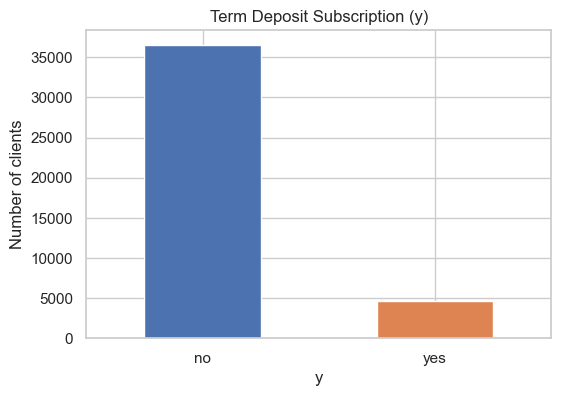

In [6]:
target_counts = df["y"].value_counts()
print(pd.DataFrame({"count": target_counts, "percent": (target_counts / len(df) * 100).round(2)}))

target_counts.plot(kind="bar", color=["#4C72B0", "#DD8452"], figsize=(6, 4), rot=0)
plt.title("Term Deposit Subscription (y)")
plt.ylabel("Number of clients")
plt.show()

The target is heavily imbalanced: only about 11% of the calls ended in a subscription. Plain accuracy would therefore mislead, since a model that always predicts "no" is right about 89% of the time. This affects the modelling stage, which uses class weighting and looks at recall.

### 4.3 Numerical Features

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


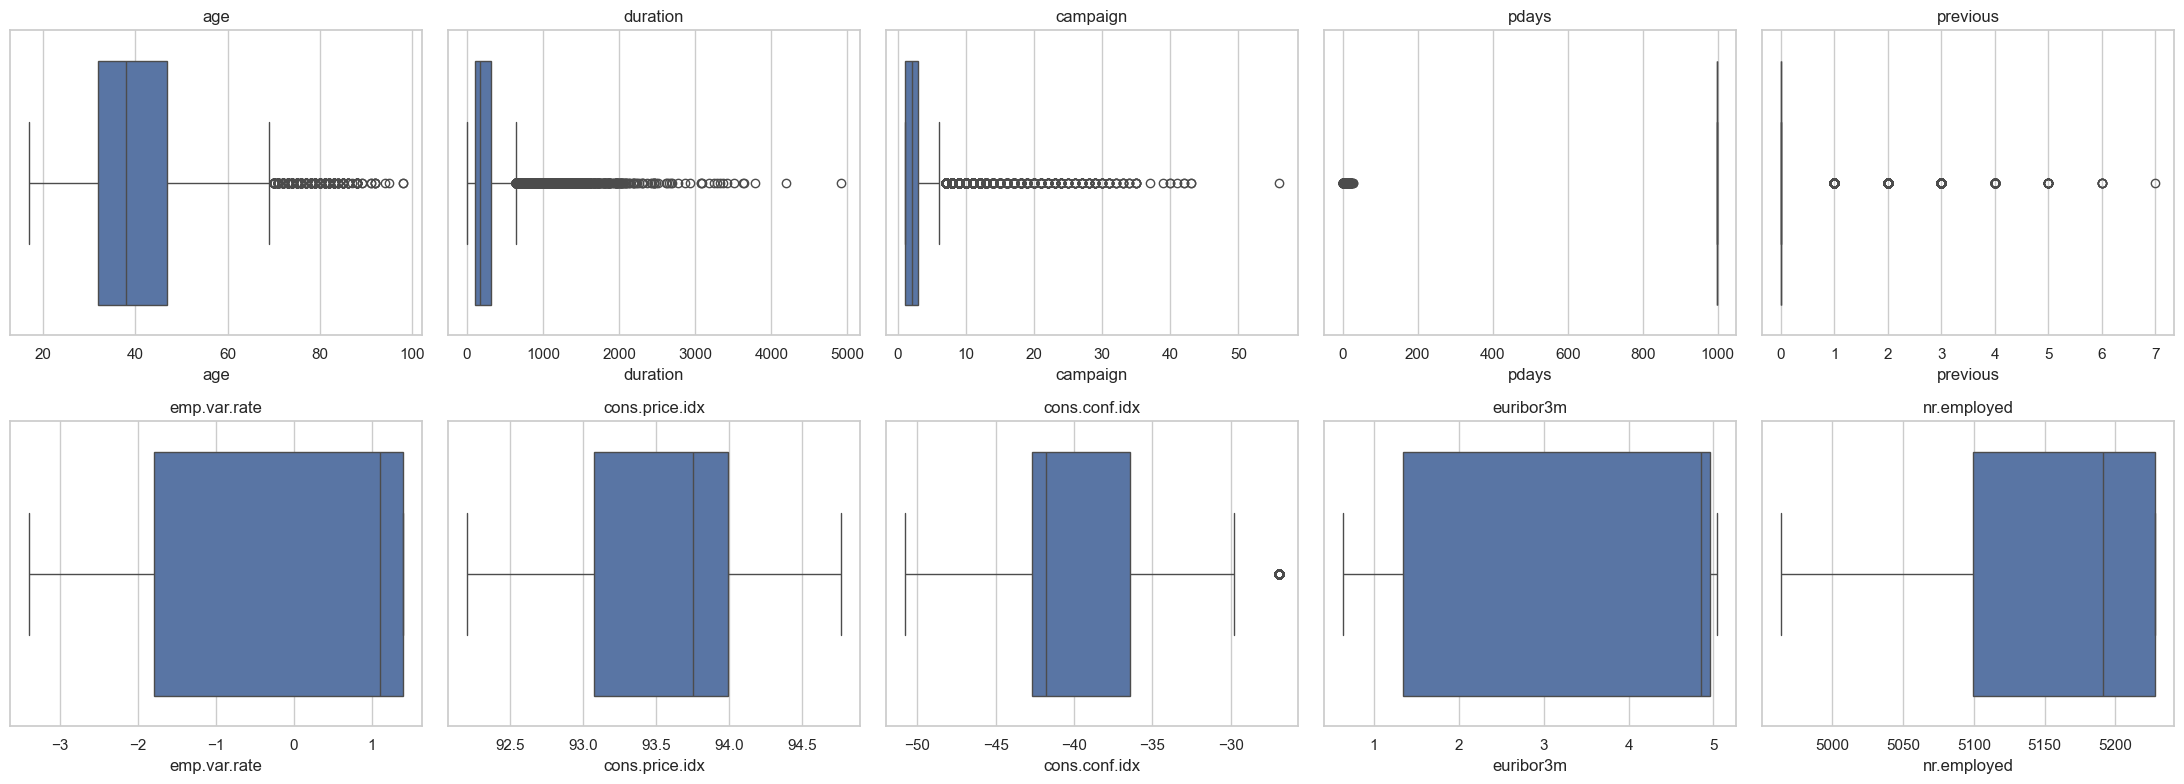

In [8]:
num_cols = df.select_dtypes(include=np.number).columns

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [9]:
def count_iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum()


outliers = pd.Series({col: count_iqr_outliers(df[col]) for col in num_cols}, name="outliers")
pd.DataFrame({"outliers": outliers, "percent": (outliers / len(df) * 100).round(2)})

,outliers,percent
age,469,1.14
duration,2963,7.19
campaign,2406,5.84
pdays,1515,3.68
previous,5625,13.66
emp.var.rate,0,0.00
cons.price.idx,0,0.00
cons.conf.idx,447,1.09
euribor3m,0,0.00
nr.employed,0,0.00


In [10]:
print("pdays value share (%):")
print((df["pdays"].value_counts(normalize=True).head() * 100).round(2))

pdays value share (%):
pdays
999    96.32
3       1.07
6       1.00
4       0.29
9       0.16
Name: proportion, dtype: float64


- `campaign`, `duration`, `age` and `previous` have long right tails. For example, some clients were called dozens of times in a single campaign. These values are real, so they stay in the data. A scaler based on the median and IQR (`RobustScaler`) limits their influence instead.
- `pdays` equals the placeholder 999 ("never contacted before") in about 96% of rows, so it carries almost no numeric information. It is dropped, and `previous` / `poutcome` already capture the contact history.
- `duration` is the length of the call, which is only known *after* the call ends. Using it to predict the call's outcome would leak the answer, so it is dropped as well.

### 4.4 Categorical Features

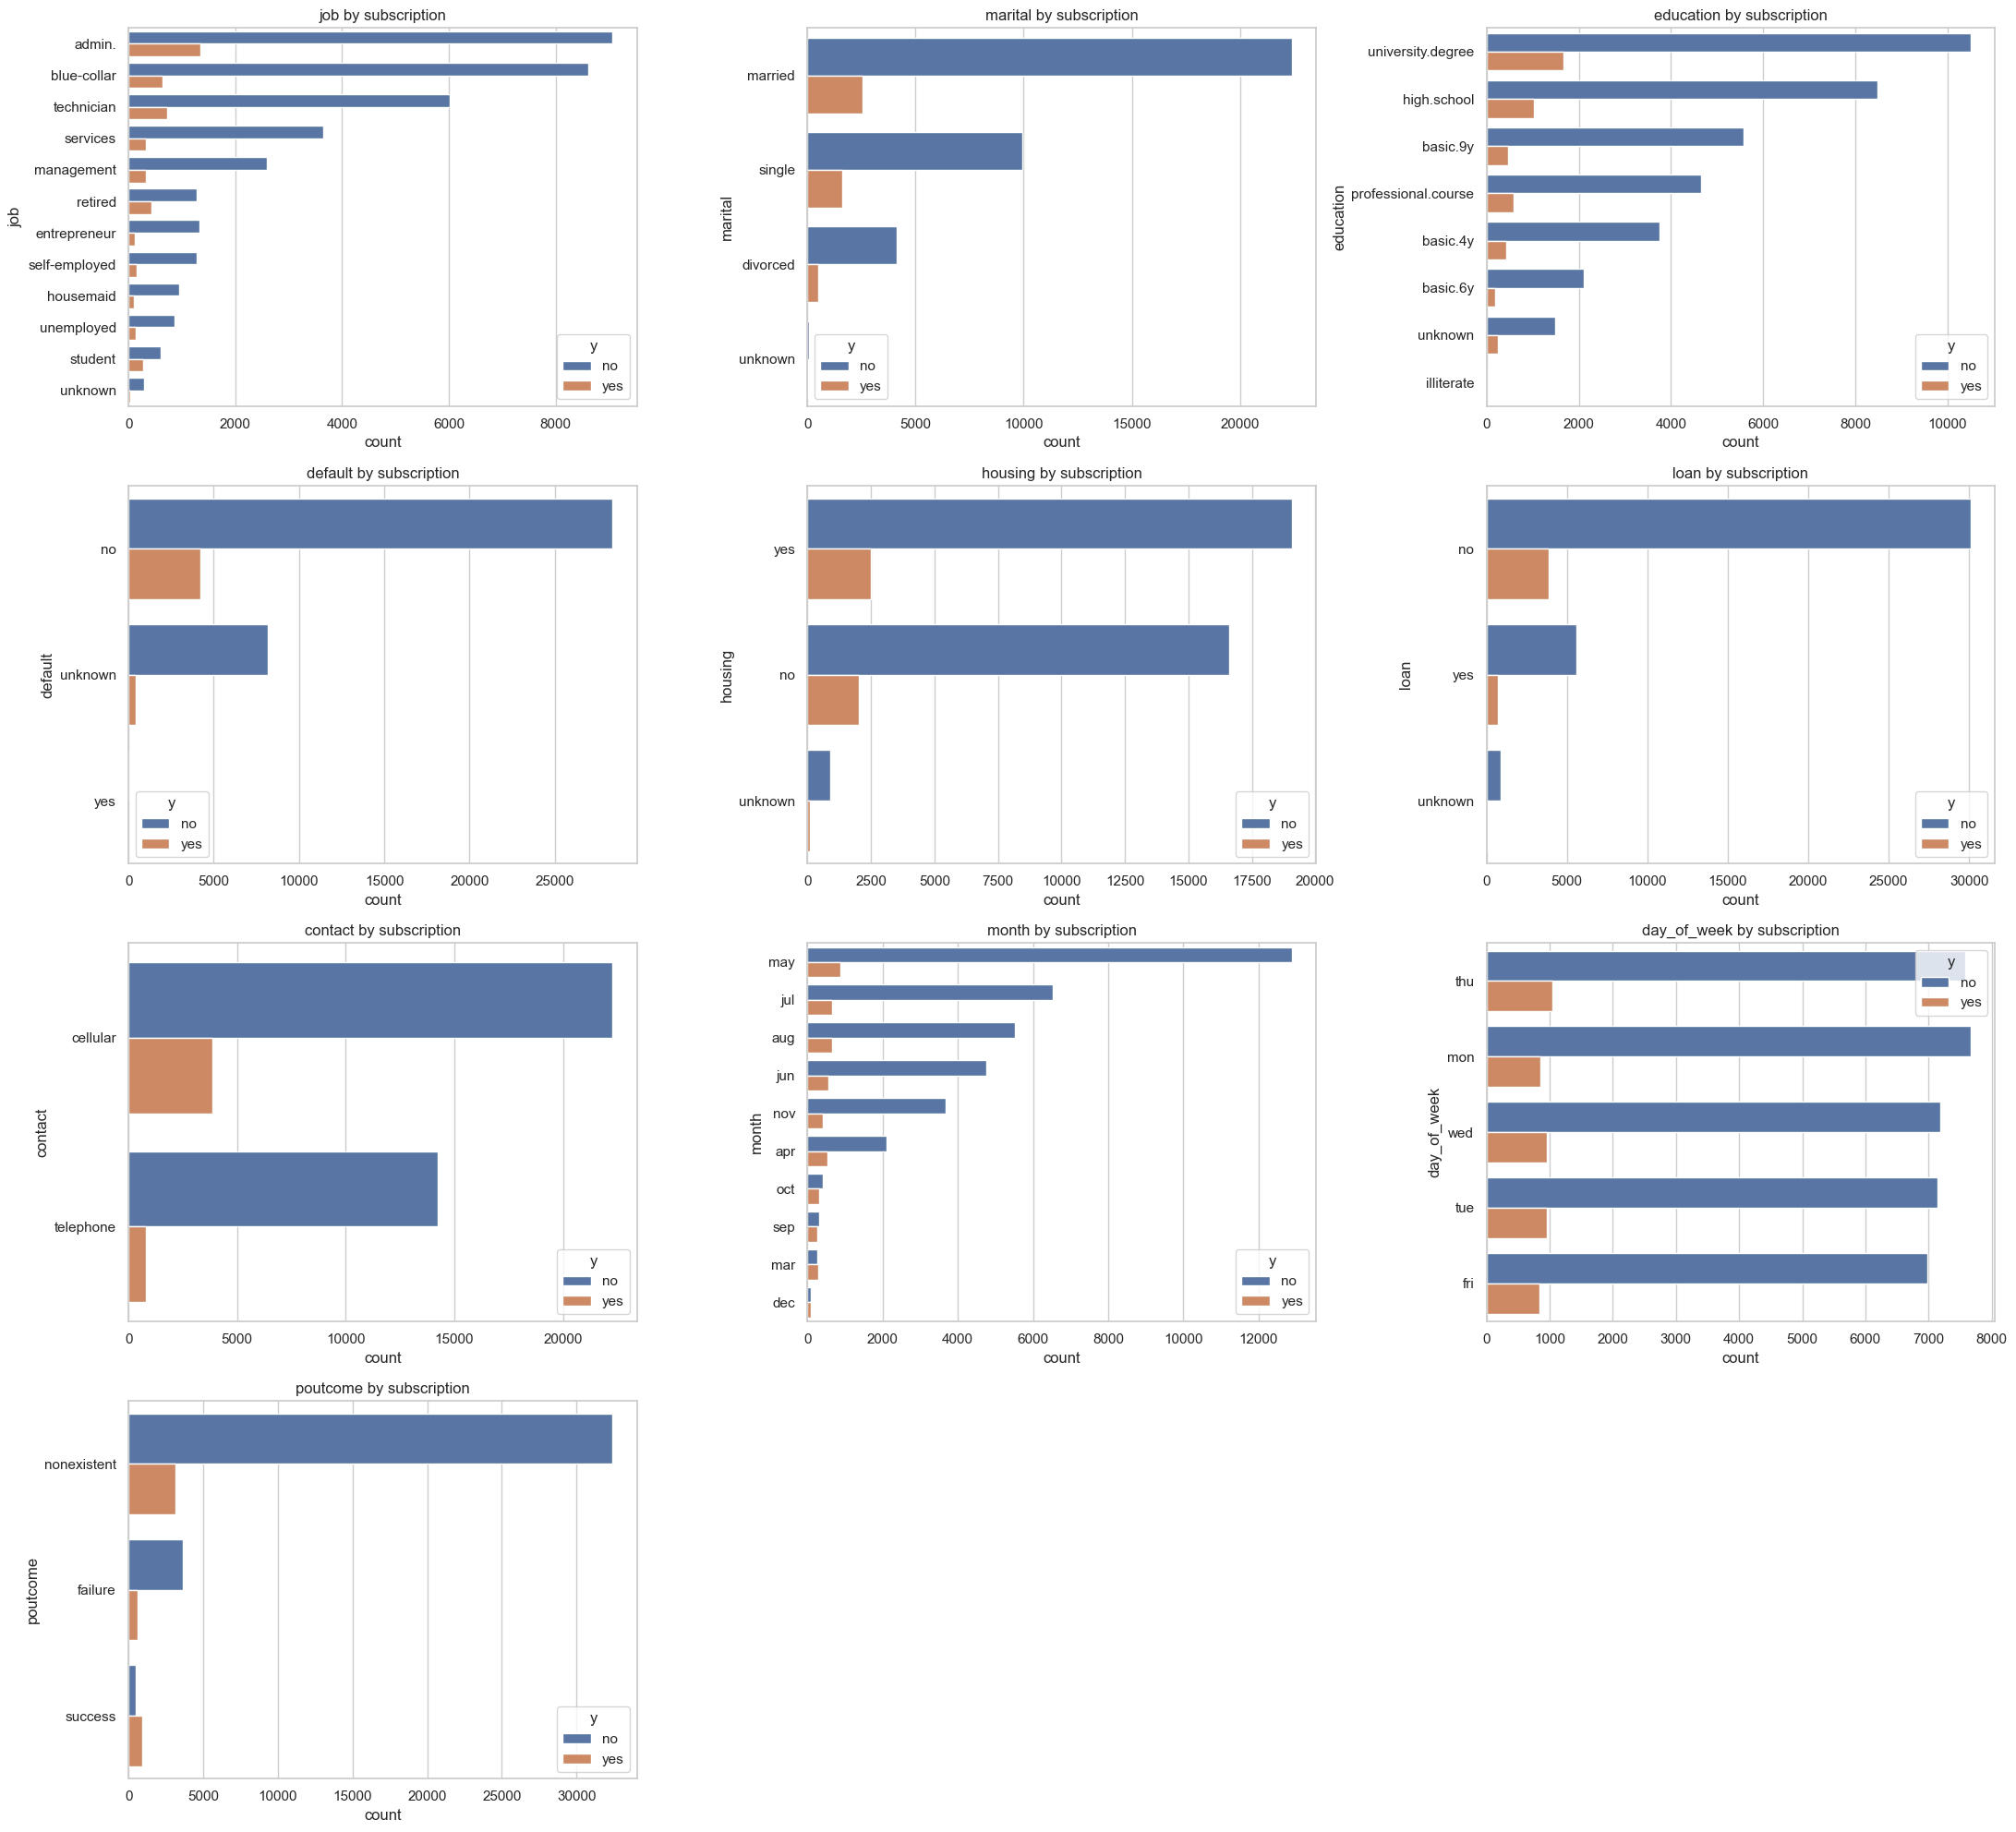

In [11]:
cat_cols = df.select_dtypes(include="object").columns.drop("y")

fig, axes = plt.subplots(4, 3, figsize=(22, 20))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(y=col, hue="y", data=df, order=df[col].value_counts().index, ax=ax)
    ax.set_title(f"{col} by subscription")
for ax in axes.ravel()[len(cat_cols):]:
    ax.remove()
plt.tight_layout()
plt.show()

In [12]:
subscription_rate = {
    col: (df.groupby(col)["y"].apply(lambda s: (s == "yes").mean() * 100).round(2).sort_values(ascending=False))
    for col in ["job", "contact", "month", "poutcome"]
}
for col, rate in subscription_rate.items():
    print(f"Subscription rate (%) by {col}:\n{rate}\n")

Subscription rate (%) by job:
job
student          31.43
retired          25.23
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.89
Name: y, dtype: float64

Subscription rate (%) by contact:
contact
cellular     14.74
telephone     5.23
Name: y, dtype: float64

Subscription rate (%) by month:
month
mar    50.55
dec    48.90
sep    44.91
oct    43.87
apr    20.48
aug    10.60
jun    10.51
nov    10.14
jul     9.05
may     6.43
Name: y, dtype: float64

Subscription rate (%) by poutcome:
poutcome
success        65.11
failure        14.23
nonexistent     8.83
Name: y, dtype: float64



- Clients whose previous campaign was a `success` subscribe far more often than everyone else. `poutcome` is therefore a strong signal.
- `cellular` contacts convert better than `telephone`, and months with few calls (March, September, October, December) have much higher success rates than May, when most calls were made.
- Students and retired clients have the highest subscription rates among the job categories.

### 4.5 The "unknown" Category and Rare Levels

In [13]:
unknown = (df[cat_cols] == "unknown").sum()
unknown = unknown[unknown > 0]
pd.DataFrame({"unknown": unknown, "percent": (unknown / len(df) * 100).round(2)})

,unknown,percent
job,330,0.80
marital,80,0.19
education,1731,4.20
default,8597,20.87
housing,990,2.40
loan,990,2.40


In [14]:
print(df["education"].value_counts(), "\n")
print(df["default"].value_counts())

education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64 

default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64


- `marital` has only a few dozen `"unknown"` rows. Removing them costs almost nothing.
- `default` is about 21% `"unknown"`, and `job`, `education`, `housing` and `loan` also contain `"unknown"`. There are too many to drop, and the fact that a value is unknown may itself be informative, so `"unknown"` stays as its own category in these columns.
- `education = "illiterate"` (18 rows) and `default = "yes"` (3 rows) are almost empty categories. They would become one-hot columns that are nearly always zero, so those rows are removed.

### 4.6 Correlation of Numerical Features

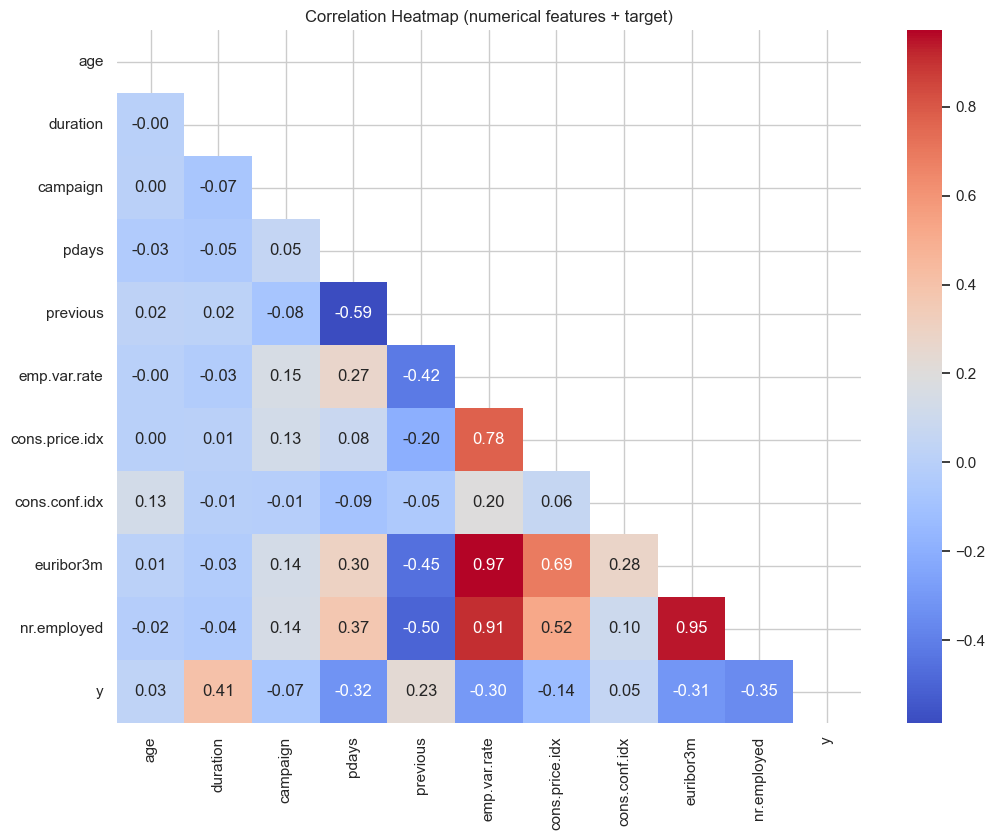

In [15]:
corr = df[num_cols].assign(y=(df["y"] == "yes").astype(int)).corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", mask=np.triu(np.ones_like(corr, dtype=bool)))
plt.title("Correlation Heatmap (numerical features + target)")
plt.show()

`emp.var.rate`, `euribor3m` and `nr.employed` are strongly correlated with each other (|r| > 0.9) because they all describe the same economic cycle. Among the features that are available before a call, `nr.employed` has the strongest (negative) correlation with the target. `duration` correlates strongly with the target too, but that is exactly the leakage explained above.

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

### 5.1 Encode the Target and Drop Leakage / Low-information Columns

In [16]:
data = df.copy()
data = data.rename(columns={"y": "deposit"})
data["deposit"] = data["deposit"].map({"yes": 1, "no": 0})
data = data.drop(columns=["duration", "pdays"])
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,deposit
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0


### 5.2 Remove Duplicates

In [17]:
print("Duplicates before:", data.duplicated().sum())
data = data.drop_duplicates()
print("Duplicates after :", data.duplicated().sum(), "| shape:", data.shape)

Duplicates before: 1795
Duplicates after : 0 | shape: (39393, 19)


Dropping `duration` and `pdays` creates additional duplicates, because some rows now differ only in those columns. All of them are removed here.

### 5.3 Remove Rare / Noisy Categories

In [18]:
data = data[data["marital"] != "unknown"]
data = data[data["education"] != "illiterate"]
data = data[data["default"] != "yes"]
print("Shape after filtering:", data.shape)

Shape after filtering: (39294, 19)


### 5.4 Train-Test Split

In [19]:
X = data.drop(columns=["deposit"])
y = data["deposit"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Positive rate  train: {:.4f} | test: {:.4f}".format(y_train.mean(), y_test.mean()))

Train: (31435, 18) | Test: (7859, 18)
Positive rate  train: 0.1165 | test: 0.1164


The split happens **before** scaling and encoding, so the scaler and encoder learn only from the training data. `stratify=y` keeps the roughly 11% positive rate the same in both sets.

### 5.5 Scale Numerical Features (RobustScaler)

In [20]:
num_features = X_train.select_dtypes(include=np.number).columns

scaler = RobustScaler()
X_train_num = pd.DataFrame(scaler.fit_transform(X_train[num_features]), columns=num_features)
X_test_num = pd.DataFrame(scaler.transform(X_test[num_features]), columns=num_features)
X_train_num.describe().T[["mean", "50%", "min", "max"]]

,mean,50%,min,max
age,0.142974,0.0,-1.400000,3.800000
campaign,0.305313,0.0,-0.500000,27.000000
previous,0.177636,0.0,0.000000,6.000000
emp.var.rate,-0.323271,0.0,-1.406250,0.093750
cons.price.idx,-0.239269,0.0,-1.737758,1.054407
cons.conf.idx,0.205781,0.0,-1.428571,2.365079
euribor3m,-0.345744,0.0,-1.164323,0.051833
nr.employed,-0.192972,0.0,-1.762791,0.287597


### 5.6 Encode Categorical Features (One-Hot)

In [21]:
cat_features = X_train.select_dtypes(include="object").columns

encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
X_train_cat = pd.DataFrame(encoder.fit_transform(X_train[cat_features]), columns=encoder.get_feature_names_out())
X_test_cat = pd.DataFrame(encoder.transform(X_test[cat_features]), columns=encoder.get_feature_names_out())
print("Encoded categorical columns:", X_train_cat.shape[1])

Encoded categorical columns: 40


`drop="first"` removes one redundant column per feature, which avoids perfect multicollinearity. `handle_unknown="ignore"` protects inference: a category never seen during training is encoded as all zeros instead of raising an error.

### 5.7 Combine and Save the Preprocessed Dataset

In [22]:
train_df = pd.concat([X_train_num, X_train_cat, y_train.reset_index(drop=True)], axis=1)
test_df = pd.concat([X_test_num, X_test_cat, y_test.reset_index(drop=True)], axis=1)

OUTPUT_DIR = "bankmarketing_preprocessing"
os.makedirs(OUTPUT_DIR, exist_ok=True)
train_df.to_csv(os.path.join(OUTPUT_DIR, "train.csv"), index=False, lineterminator="\n")
test_df.to_csv(os.path.join(OUTPUT_DIR, "test.csv"), index=False, lineterminator="\n")

print("train.csv:", train_df.shape, "| test.csv:", test_df.shape)
print("Missing values after preprocessing:", int(train_df.isna().sum().sum() + test_df.isna().sum().sum()))
train_df.head()

train.csv: (31435, 49) | test.csv: (7859, 49)
Missing values after preprocessing: 0


,age,campaign,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_married,marital_single,education_basic.6y,education_basic.9y,education_high.school,education_professional.course,education_university.degree,education_unknown,default_unknown,housing_unknown,housing_yes,loan_unknown,loan_yes,contact_telephone,month_aug,month_dec,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success,deposit
0,0.000000,-0.5,0.0,-0.90625,-0.984766,-0.698413,-0.977116,-0.712403,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
1,0.933333,0.0,0.0,0.09375,-0.385201,0.904762,0.030604,0.287597,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0
2,-0.333333,0.0,0.0,-1.25000,-0.908596,0.158730,-0.991729,-0.889922,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0
3,-0.533333,-0.5,0.0,0.09375,-0.385201,0.904762,0.029501,0.287597,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
4,1.733333,-0.5,2.0,-1.25000,-1.737758,1.650794,-1.095396,-0.889922,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0


The final dataset is fully numeric and ready for training: the scaled numeric features, the one-hot encoded categorical features, and the target `deposit`. It is saved to `preprocessing/bankmarketing_preprocessing/` (`train.csv`, `test.csv`). The same steps, in the same order, are automated in `automate_Kevin-Aditya-Ikhsan.py`, which produces identical files.